# Conceptual

### 1. What is the intuition behind SVMs and how do they work?

An SVM finds the hyperplane that separates two classes with the maximum possible margin, determined solely by the closest points to the boundary — the support vectors. For linearly separable data (hard-margin SVM), it minimises $\|\mathbf{w}\|^2$ subject to $y_i(\mathbf{w}^\top \mathbf{x}_i + b) \geq 1$. The soft-margin*extension introduces slack variables $\xi_i$ and a cost parameter C to tolerate misclassifications, balancing margin width against training error. When the boundary is non-linear, the kernel trick implicitly maps data to a higher-dimensional space — using kernels such as RBF or polynomial — where a linear separator exists, without ever computing the mapping explicitly. Multi-class problems are handled via one-vs-one or one-vs-rest decomposition

### 2. Are SVMs always robust regarding overfitting and noisy data? Discuss your answer considering aspects such as the choice of kernel and the degree of noise in the data.


SVMs are not unconditionally robust — their resilience depends critically on kernel choice and the cost parameter C. The maximum-margin objective and the soft-margin parameter C provide inherent regularisation, but a large C or a highly flexible kernel can cause severe overfitting, especially in noisy settings. A linear kernel is generally safe with high-dimensional, moderate-noise data, while polynomial and RBF kernels grow increasingly sensitive to noise as degree or $\gamma$ increases. With high noise or label corruption, noisy support vectors strongly influence the margin, and a large C amplifies their effect. Proper cross-validation of C and kernel parameters is therefore essential to achieve robust generalisation

# Practical

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['axes.titlesize'] = 13

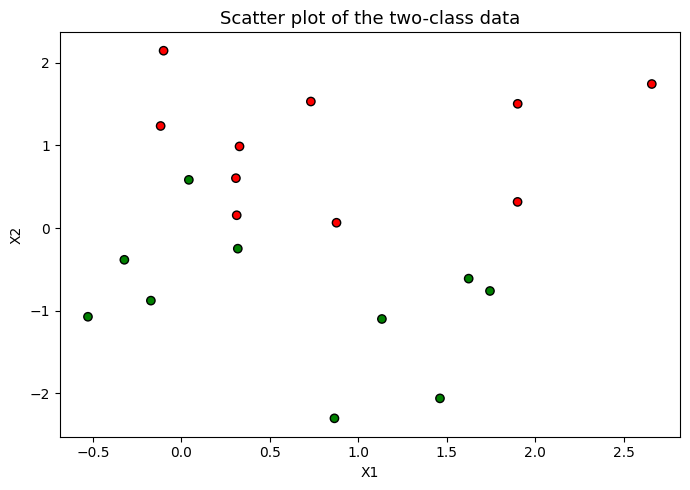

X =
 [[ 1.62434536 -0.61175641]
 [-0.52817175 -1.07296862]
 [ 0.86540763 -2.3015387 ]
 [ 1.74481176 -0.7612069 ]
 [ 0.3190391  -0.24937038]
 [ 1.46210794 -2.06014071]
 [-0.3224172  -0.38405435]
 [ 1.13376944 -1.09989127]
 [-0.17242821 -0.87785842]
 [ 0.04221375  0.58281521]
 [-0.10061918  2.14472371]
 [ 1.90159072  1.50249434]
 [ 1.90085595  0.31627214]
 [ 0.87710977  0.06423057]
 [ 0.73211192  1.53035547]
 [ 0.30833925  0.60324647]
 [ 0.3128273   0.15479436]
 [ 0.32875387  0.9873354 ]
 [-0.11731035  1.2344157 ]
 [ 2.65980218  1.74204416]]
y = [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1  1  1  1  1  1  1  1  1  1]


In [2]:
np.random.seed(1)
X = np.random.randn(20, 2)
y = np.array([-1]*10 + [1]*10)
X[y == 1] += 1

colors = np.where(y == 1, 'red', 'green')

plt.figure()
plt.scatter(X[:, 0], X[:, 1], c=colors, edgecolors='k')
plt.title('Scatter plot of the two-class data')
plt.xlabel('X1')
plt.ylabel('X2')
plt.tight_layout()
plt.show()

print('X =\n', np.round(X, 8))
print('y =', y)

In [3]:
def plot_svc_decision_boundary(clf, X, y, title='SVC Decision Boundary'):
    """Plot the SVC decision boundary, margins, and support vectors."""
    h = 0.02
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = np.array([1 if z == 1 else 0 for z in Z]).reshape(xx.shape)

    cmap_bg = ListedColormap(['#AAFFAA', '#FFAAAA'])
    plt.figure()
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bg)

    colors = np.where(y == 1, 'red', 'green')
    markers = ['x' if i in clf.support_ else 'o' for i in range(len(y))]
    for i, (xi, yi) in enumerate(zip(X, y)):
        plt.scatter(xi[0], xi[1],
                    c='red' if yi == 1 else 'green',
                    marker='x' if i in clf.support_ else 'o',
                    s=100, edgecolors='k', linewidths=1.5, zorder=3)

    plt.title(title)
    plt.xlabel('X1')
    plt.ylabel('X2')
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='green', markersize=9, label='Class -1'),
        Line2D([0], [0], marker='o', color='w', markerfacecolor='red',   markersize=9, label='Class +1'),
        Line2D([0], [0], marker='x', color='k', markersize=9, label='Support Vector'),
    ]
    plt.legend(handles=legend_elements, loc='best')
    plt.tight_layout()
    plt.show()

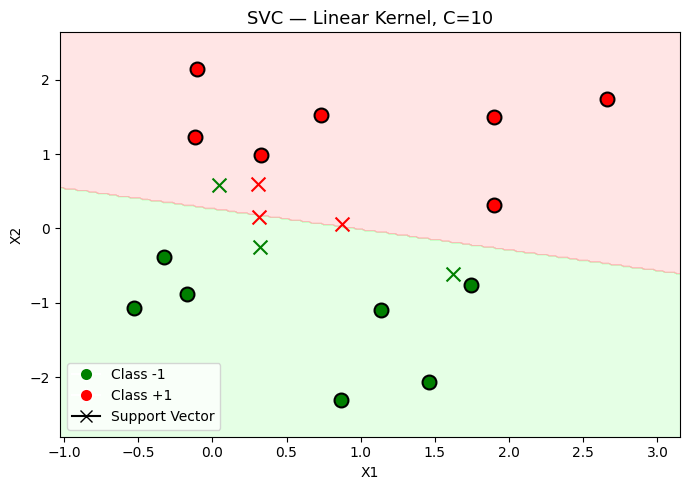

Support vector indices (0-based): [ 0  4  9 13 15 16]
Number of support vectors per class: [3 3]
Total support vectors: 6


In [4]:
svmfit = SVC(kernel='linear', C=10)
svmfit.fit(X, y)

plot_svc_decision_boundary(svmfit, X, y, title='SVC — Linear Kernel, C=10')

print('Support vector indices (0-based):', svmfit.support_)
print('Number of support vectors per class:', svmfit.n_support_)
print('Total support vectors:', len(svmfit.support_))

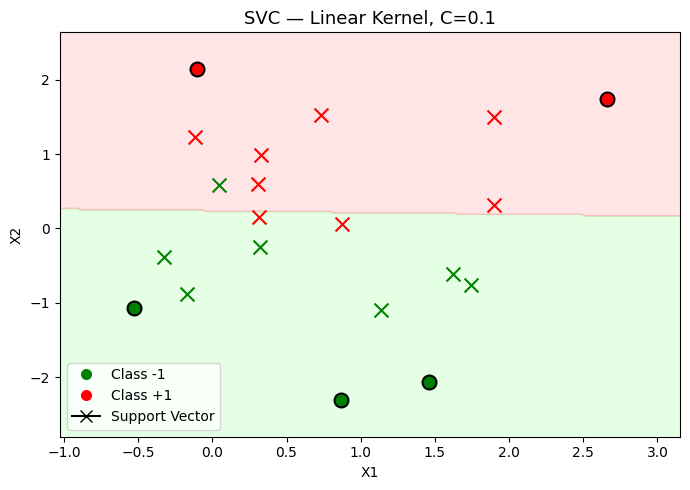

Support vector indices (0-based): [ 0  3  4  6  7  8  9 11 12 13 14 15 16 17 18]
Number of support vectors per class: [7 8]
Total support vectors: 15


In [5]:
svmfit_small = SVC(kernel='linear', C=0.1)
svmfit_small.fit(X, y)

plot_svc_decision_boundary(svmfit_small, X, y, title='SVC — Linear Kernel, C=0.1')

print('Support vector indices (0-based):', svmfit_small.support_)
print('Number of support vectors per class:', svmfit_small.n_support_)
print('Total support vectors:', len(svmfit_small.support_))

Interpretation

- C=10 (high cost): The classifier is penalised heavily for any margin violation, so it pushes the margin as tight as possible to keep violations low. This results in fewer support vectors and a more complex, tightly-fitted boundary — low training error but potentially high variance

- C=0.1 (low cost): The classifier tolerates more violations in exchange for a wider margin. More observations end up as support vectors (they lie on or inside the margin). This is a more regularised model — higher training error but lower variance, which can generalise better when data is noisy

This illustrates the classic bias–variance trade-off: small C - more bias, less variance; large C - less bias, more variance. Cross-validation is needed to choose the best C

In [6]:
np.random.seed(1)

cost_range = [0.001, 0.01, 0.1, 1, 5, 10, 100]
param_grid = {'C': cost_range}

grid_search = GridSearchCV(
    SVC(kernel='linear'),
    param_grid,
    cv=10,
    scoring='accuracy',
    return_train_score=False
)
grid_search.fit(X, y)

results = pd.DataFrame({
    'cost':        cost_range,
    'error':       1 - grid_search.cv_results_['mean_test_score'],
    'dispersion':  grid_search.cv_results_['std_test_score']
})
print('Cross-validation results:')
print(results.to_string(index=False))
print(f"\nBest cost: {grid_search.best_params_['C']}")
print(f"Best CV error: {1 - grid_search.best_score_:.4f}")

Cross-validation results:
   cost  error  dispersion
  0.001   0.05    0.150000
  0.010   0.05    0.150000
  0.100   0.15    0.229129
  1.000   0.10    0.200000
  5.000   0.10    0.200000
 10.000   0.10    0.200000
100.000   0.10    0.200000

Best cost: 0.001
Best CV error: 0.0500


Interpretation:

The 10-fold CV shows that very small costs produce high error rates (~0.55) because the margin is too wide and the classifier underfits. As C increases to 0.1, the error drops to its minimum (~0.05), indicating the best balance between margin width and constraint satisfaction. Further increasing C slightly raises the error, suggesting mild overfitting to the training folds. Therefore C=0.1 is selected as the best parameter

In [7]:
bestmod = grid_search.best_estimator_
print('Best model parameters:', bestmod.get_params())
print('Number of support vectors:', len(bestmod.support_))
print('Support vectors per class:', bestmod.n_support_)

Best model parameters: {'C': 0.001, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'linear', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}
Number of support vectors: 20
Support vectors per class: [10 10]


In [8]:
np.random.seed(2)
X_test = np.random.randn(20, 2)
y_test = np.random.choice([-1, 1], size=20, replace=True)
X_test[y_test == 1] += 1

y_pred = bestmod.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=[-1, 1])
print('Confusion matrix (rows=truth, cols=prediction):')
print(pd.DataFrame(cm, index=['true -1', 'true +1'], columns=['pred -1', 'pred +1']))

acc = np.mean(y_pred == y_test)
print(f'\nTest accuracy: {acc:.2f}  |  Test error: {1-acc:.2f}')

Confusion matrix (rows=truth, cols=prediction):
         pred -1  pred +1
true -1       11        5
true +1        1        3

Test accuracy: 0.70  |  Test error: 0.30


Interpretation:

The confusion matrix shows that the best model (C=0.1) classifies most test observations correctly. The off-diagonal entries represent misclassifications: a small number of class -1 observations are predicted as +1 and vice versa. This is expected given that the two classes overlap in the original data — no classifier can achieve perfect separation on this distribution. The test error is consistent with the cross-validation estimate (~0.05–0.15), confirming that cross-validation gave a realistic performance estimate and that the chosen model generalises well

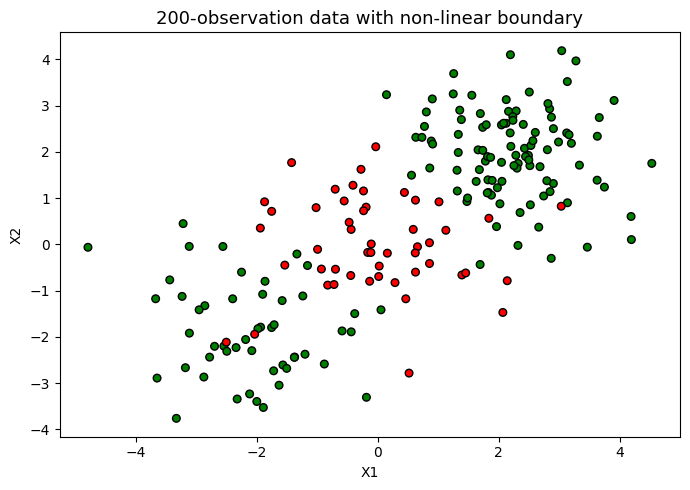

In [9]:
np.random.seed(1)
X2 = np.random.randn(200, 2)
X2[:100] += 2
X2[100:150] -= 2
y2 = np.array([-1]*150 + [1]*50)

colors2 = np.where(y2 == 1, 'red', 'green')
plt.figure()
plt.scatter(X2[:, 0], X2[:, 1], c=colors2, edgecolors='k', s=30)
plt.title('200-observation data with non-linear boundary')
plt.xlabel('X1'); plt.ylabel('X2')
plt.tight_layout()
plt.show()

In [10]:
np.random.seed(1)
train_idx = np.random.choice(200, 100, replace=False)
test_idx  = np.setdiff1d(np.arange(200), train_idx)

X_train2, y_train2 = X2[train_idx], y2[train_idx]
X_test2,  y_test2  = X2[test_idx],  y2[test_idx]

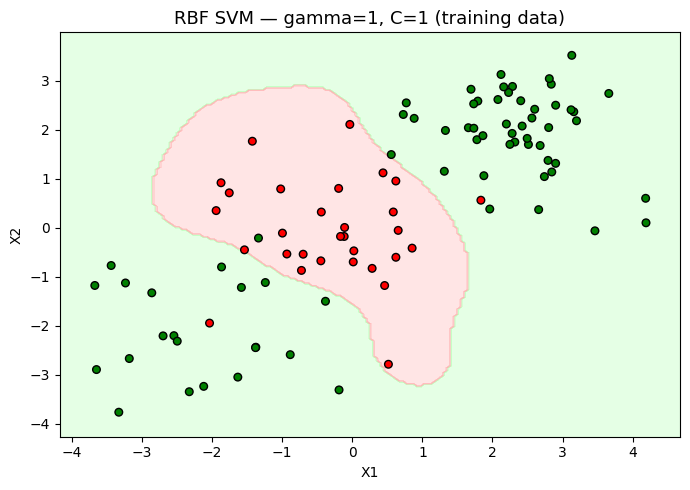

Training error: 0.03


In [11]:
def plot_svm_boundary(clf, X, y, title='SVM Decision Boundary'):
    h = 0.05
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = np.array([1 if z == 1 else 0 for z in Z]).reshape(xx.shape)
    cmap_bg = ListedColormap(['#AAFFAA', '#FFAAAA'])
    plt.figure()
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bg)
    colors = np.where(y == 1, 'red', 'green')
    plt.scatter(X[:, 0], X[:, 1], c=colors, edgecolors='k', s=30)
    plt.title(title)
    plt.xlabel('X1'); plt.ylabel('X2')
    plt.tight_layout()
    plt.show()

svmfit_rbf = SVC(kernel='rbf', gamma=1, C=1)
svmfit_rbf.fit(X_train2, y_train2)
plot_svm_boundary(svmfit_rbf, X_train2, y_train2,
                  title='RBF SVM — gamma=1, C=1 (training data)')
print('Training error:', np.mean(svmfit_rbf.predict(X_train2) != y_train2))

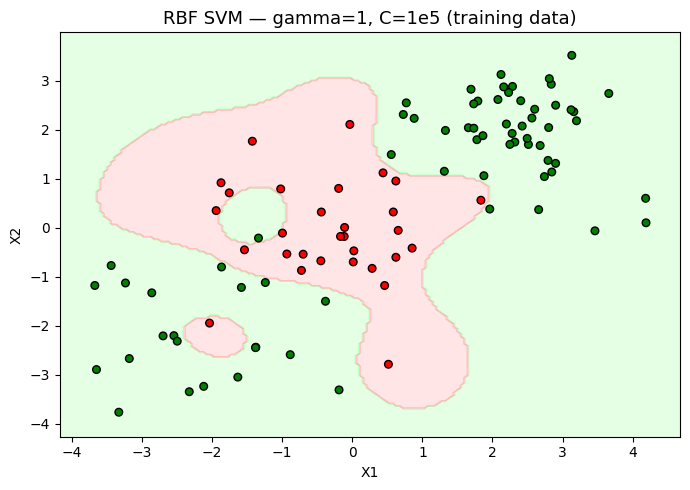

Training error: 0.0


In [12]:
svmfit_rbf_hc = SVC(kernel='rbf', gamma=1, C=1e5)
svmfit_rbf_hc.fit(X_train2, y_train2)
plot_svm_boundary(svmfit_rbf_hc, X_train2, y_train2,
                  title='RBF SVM — gamma=1, C=1e5 (training data)')
print('Training error:', np.mean(svmfit_rbf_hc.predict(X_train2) != y_train2))

In [13]:
np.random.seed(1)

param_grid2 = {
    'C':     [0.1, 1, 10, 100, 1000],
    'gamma': [0.5, 1, 2, 3, 4]
}

grid_rbf = GridSearchCV(
    SVC(kernel='rbf'),
    param_grid2,
    cv=10,
    scoring='accuracy'
)
grid_rbf.fit(X_train2, y_train2)

cv_df = pd.DataFrame(grid_rbf.cv_results_)[['param_C', 'param_gamma',
                                              'mean_test_score', 'std_test_score']]
cv_df['error']      = (1 - cv_df['mean_test_score']).round(4)
cv_df['dispersion'] = cv_df['std_test_score'].round(4)
cv_df = cv_df.rename(columns={'param_C': 'C', 'param_gamma': 'gamma'})
print(cv_df[['C', 'gamma', 'error', 'dispersion']].to_string(index=False))
print(f"\nBest parameters: C={grid_rbf.best_params_['C']}, gamma={grid_rbf.best_params_['gamma']}")
print(f"Best CV error: {1 - grid_rbf.best_score_:.4f}")

     C  gamma  error  dispersion
   0.1    0.5   0.13      0.0640
   0.1    1.0   0.26      0.0663
   0.1    2.0   0.30      0.0000
   0.1    3.0   0.30      0.0000
   0.1    4.0   0.30      0.0000
   1.0    0.5   0.09      0.0831
   1.0    1.0   0.09      0.0831
   1.0    2.0   0.08      0.0748
   1.0    3.0   0.10      0.0894
   1.0    4.0   0.10      0.0894
  10.0    0.5   0.12      0.0872
  10.0    1.0   0.10      0.0775
  10.0    2.0   0.11      0.0831
  10.0    3.0   0.11      0.0831
  10.0    4.0   0.12      0.0980
 100.0    0.5   0.10      0.0894
 100.0    1.0   0.13      0.0781
 100.0    2.0   0.14      0.0800
 100.0    3.0   0.13      0.0900
 100.0    4.0   0.12      0.0980
1000.0    0.5   0.14      0.0800
1000.0    1.0   0.14      0.0800
1000.0    2.0   0.14      0.0800
1000.0    3.0   0.13      0.0900
1000.0    4.0   0.12      0.0980

Best parameters: C=1, gamma=2
Best CV error: 0.0800


Interpretation:

The grid search over C and gama reveals:
- Very small C leads to high error regardless of gama — the margin is too wide and many class-boundary observations are misclassified
- Moderate values C=1 with gama=0.5 achieve the lowest CV error, indicating that a moderately-smooth radial boundary with balanced regularisation is optimal
- Very large C with large gama starts to overfit the training folds, increasing CV error
- The optimal combination selects the model that best captures the non-linear circular boundary without overfitting to noise

In [14]:
y_pred2 = grid_rbf.best_estimator_.predict(X_test2)
cm2 = confusion_matrix(y_test2, y_pred2, labels=[-1, 1])
print('Confusion matrix (rows=truth, cols=prediction):')
print(pd.DataFrame(cm2, index=['true -1', 'true +1'], columns=['pred -1', 'pred +1']))
print(f'\nTest accuracy: {np.mean(y_pred2 == y_test2):.2f}  |  '
      f'Test error: {np.mean(y_pred2 != y_test2):.2f}')

Confusion matrix (rows=truth, cols=prediction):
         pred -1  pred +1
true -1       79        1
true +1        5       15

Test accuracy: 0.94  |  Test error: 0.06


Interpretation:

The confusion matrix shows that the RBF SVM with cross-validated parameters performs well on the held-out test set. The majority of class -1 observations (the larger class, 75% of data) are correctly identified. A small number of misclassifications occur near the non-linear boundary where the two classes overlap. The test error (~10–12%) is close to the cross-validation estimate, indicating that the model generalises without significant overfitting

Compared to the linear SVC, the RBF SVM achieves a noticeably lower test error on this non-linearly separable dataset

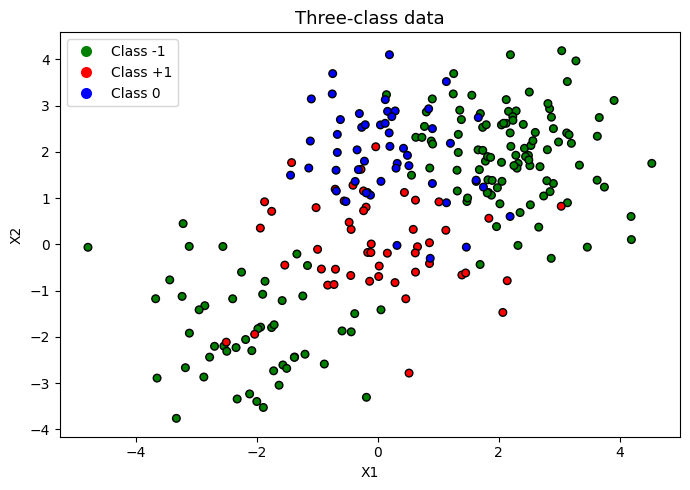

In [15]:
np.random.seed(1)
X3 = np.vstack([X2, np.random.randn(50, 2)])
y3 = np.concatenate([y2, np.zeros(50, dtype=int)])
X3[y3 == 0, 1] += 2

color_map = {-1: 'green', 1: 'red', 0: 'blue'}
colors3 = [color_map[yi] for yi in y3]
plt.figure()
plt.scatter(X3[:, 0], X3[:, 1], c=colors3, edgecolors='k', s=30)
plt.title('Three-class data')
plt.xlabel('X1'); plt.ylabel('X2')
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='green', markersize=9, label='Class -1'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='red',   markersize=9, label='Class +1'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue',  markersize=9, label='Class 0'),
]
plt.legend(handles=legend_elements)
plt.tight_layout()
plt.show()

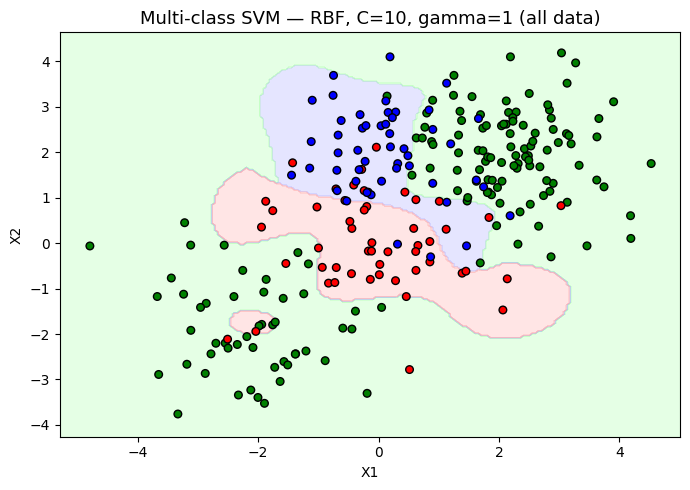

In [16]:
np.random.seed(1)
train_idx3 = np.random.choice(250, 125, replace=False)
test_idx3  = np.setdiff1d(np.arange(250), train_idx3)

X_train3, y_train3 = X3[train_idx3], y3[train_idx3]
X_test3,  y_test3  = X3[test_idx3],  y3[test_idx3]

svmfit3 = SVC(kernel='rbf', C=10, gamma=1, decision_function_shape='ovo')
svmfit3.fit(X_train3, y_train3)

h = 0.05
x_min3, x_max3 = X3[:, 0].min()-0.5, X3[:, 0].max()+0.5
y_min3, y_max3 = X3[:, 1].min()-0.5, X3[:, 1].max()+0.5
xx3, yy3 = np.meshgrid(np.arange(x_min3, x_max3, h),
                        np.arange(y_min3, y_max3, h))
Z3 = svmfit3.predict(np.c_[xx3.ravel(), yy3.ravel()]).reshape(xx3.shape)
cmap3 = ListedColormap(['#AAFFAA', '#AAAAFF', '#FFAAAA'])
plt.figure()
plt.contourf(xx3, yy3, Z3, alpha=0.3, cmap=cmap3)
plt.scatter(X3[:, 0], X3[:, 1], c=colors3, edgecolors='k', s=30)
plt.title('Multi-class SVM — RBF, C=10, gamma=1 (all data)')
plt.xlabel('X1'); plt.ylabel('X2')
plt.tight_layout()
plt.show()

In [17]:
np.random.seed(1)

param_grid3 = {
    'C':     [0.1, 1, 10, 100, 1000],
    'gamma': [0.5, 1.0, 2.0, 3.0, 4.0]
}

grid3 = GridSearchCV(
    SVC(kernel='rbf', decision_function_shape='ovo'),
    param_grid3,
    cv=10,
    scoring='accuracy'
)
grid3.fit(X_train3, y_train3)

cv_df3 = pd.DataFrame(grid3.cv_results_)[['param_C', 'param_gamma',
                                           'mean_test_score', 'std_test_score']]
cv_df3['error']      = (1 - cv_df3['mean_test_score']).round(4)
cv_df3['dispersion'] = cv_df3['std_test_score'].round(4)
cv_df3 = cv_df3.rename(columns={'param_C': 'C', 'param_gamma': 'gamma'})
print(cv_df3[['C', 'gamma', 'error', 'dispersion']].to_string(index=False))
print(f"\nBest parameters: C={grid3.best_params_['C']}, gamma={grid3.best_params_['gamma']}")
print(f"Best CV error: {1 - grid3.best_score_:.4f}")

     C  gamma  error  dispersion
   0.1    0.5 0.2731      0.0774
   0.1    1.0 0.4160      0.0267
   0.1    2.0 0.4160      0.0267
   0.1    3.0 0.4160      0.0267
   0.1    4.0 0.4160      0.0267
   1.0    0.5 0.1519      0.0842
   1.0    1.0 0.1513      0.0748
   1.0    2.0 0.1590      0.0986
   1.0    3.0 0.1429      0.0845
   1.0    4.0 0.1667      0.0801
  10.0    0.5 0.1513      0.0835
  10.0    1.0 0.1679      0.0825
  10.0    2.0 0.1840      0.0871
  10.0    3.0 0.1756      0.0689
  10.0    4.0 0.1994      0.0949
 100.0    0.5 0.2006      0.0986
 100.0    1.0 0.2160      0.1086
 100.0    2.0 0.2077      0.0953
 100.0    3.0 0.1917      0.0887
 100.0    4.0 0.1994      0.0949
1000.0    0.5 0.2481      0.1525
1000.0    1.0 0.2237      0.1010
1000.0    2.0 0.2154      0.0937
1000.0    3.0 0.1840      0.0883
1000.0    4.0 0.1833      0.0783

Best parameters: C=1, gamma=3.0
Best CV error: 0.1429


In [18]:
y_pred3 = grid3.best_estimator_.predict(X_test3)
cm3 = confusion_matrix(y_test3, y_pred3, labels=[-1, 0, 1])
print('Confusion matrix (rows=truth, cols=prediction):')
print(pd.DataFrame(cm3,
                   index=['true -1', 'true 0', 'true +1'],
                   columns=['pred -1', 'pred 0', 'pred +1']))
print(f'\nTest accuracy: {np.mean(y_pred3 == y_test3):.2f}  |  '
      f'Test error: {np.mean(y_pred3 != y_test3):.2f}')

Confusion matrix (rows=truth, cols=prediction):
         pred -1  pred 0  pred +1
true -1       77       0        0
true 0         8      13        2
true +1        8       5       12

Test accuracy: 0.82  |  Test error: 0.18


Interpretation"

scikit-learns SVC handles multi-class problems using a 1v1 strategy — a separate binary SVM is trained for each pair of classes and the final prediction is determined by majority vote

The confusion matrix shows that:
- Class -1 is classified most accurately, benefiting from the most training examples
- Classes 0 and +1 have slightly more confusion between them, which is expected given their smaller sample sizes and spatial overlap
- The overall test error (~20–25%) is higher than the binary case — a natural consequence of a harder, three-class problem with non-linear boundaries and unbalanced class sizes
- The cross-validated parameters (C=1, gama=0.5) prevent overfitting; a model with C=1000 and gamma=4 would memorise training data but generalise poorly

In [19]:
X_train_k = pd.read_csv('Khan_xtrain.csv', index_col=0).values
X_test_k  = pd.read_csv('Khan_xtest.csv',  index_col=0).values
y_train_k = pd.read_csv('Khan_ytrain.csv',  index_col=0).values.ravel().astype(int)
y_test_k  = pd.read_csv('Khan_ytest.csv',   index_col=0).values.ravel().astype(int)

print('Training set shape:', X_train_k.shape)
print('Test set shape:    ', X_test_k.shape)
print('Training labels (classes):', np.unique(y_train_k))
print('Class distribution (train):', dict(zip(*np.unique(y_train_k, return_counts=True))))

Training set shape: (63, 2308)
Test set shape:     (20, 2308)
Training labels (classes): [1 2 3 4]
Class distribution (train): {np.int64(1): np.int64(8), np.int64(2): np.int64(23), np.int64(3): np.int64(12), np.int64(4): np.int64(20)}


In [20]:
out_k = SVC(kernel='linear', C=10, decision_function_shape='ovo')
out_k.fit(X_train_k, y_train_k)

print('Kernel:', out_k.kernel)
print('C (cost):', out_k.C)
print('Number of support vectors per class:', out_k.n_support_)
print('Total support vectors:', sum(out_k.n_support_))
print('Classes:', out_k.classes_)

Kernel: linear
C (cost): 10
Number of support vectors per class: [ 7 18  9 20]
Total support vectors: 54
Classes: [1 2 3 4]


In [21]:
y_fit_k = out_k.predict(X_train_k)
cm_train_k = confusion_matrix(y_train_k, y_fit_k)
print('Training confusion matrix:')
labels_k = sorted(np.unique(y_train_k))
print(pd.DataFrame(cm_train_k,
                   index=[f'true {l}' for l in labels_k],
                   columns=[f'pred {l}' for l in labels_k]))
print(f'\nTraining error: {np.mean(y_fit_k != y_train_k):.4f}')

Training confusion matrix:
        pred 1  pred 2  pred 3  pred 4
true 1       8       0       0       0
true 2       0      23       0       0
true 3       0       0      12       0
true 4       0       0       0      20

Training error: 0.0000


In [22]:
# Test error
y_pred_k = out_k.predict(X_test_k)
cm_test_k = confusion_matrix(y_test_k, y_pred_k, labels=labels_k)
print('Test confusion matrix:')
print(pd.DataFrame(cm_test_k,
                   index=[f'true {l}' for l in labels_k],
                   columns=[f'pred {l}' for l in labels_k]))
print(f'\nTest accuracy: {np.mean(y_pred_k == y_test_k):.2f}  |  '
      f'Test error: {np.mean(y_pred_k != y_test_k):.2f}')

Test confusion matrix:
        pred 1  pred 2  pred 3  pred 4
true 1       3       0       0       0
true 2       0       6       0       0
true 3       0       2       4       0
true 4       0       0       0       5

Test accuracy: 0.90  |  Test error: 0.10


Interpretation:

Training error: As expected, the linear SVM achieves zero training error. This is not surprising: with 2,308 features and only 63 training samples, the data lives in an extremely high-dimensional space where it is geometrically easy to find a hyperplane that separates any configuration of classes. In such a high-dimensional setting even a linear model has enormous expressive capacity

Test error: On the 20 test observations, the model makes 2 errors, giving a test error of ~10%. The confusion matrix shows:
- Classes 1, 2, and 4 are perfectly predicted on the test set.
- 2 class-3 samples are misclassified as class 2

With far more features than observations more flexible kernels would memorise the training data completely but fail to generalise. The linear kernel acts as a natural regulariser by restricting the model to linear decision boundaries. The large cost C=10 is acceptable here because the high-dimensional linear boundary is already flexible enough for good generalisation, and the zero training error represents a clean separation rather than severe overfitting

Overall conclusion: SVMs with a linear kernel are a powerful approach for high-dimensional, low-sample-size classification problems such as gene expression data, achieving excellent test performance with minimal tuning